In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np

import torch
from datasets import load_dataset, load_from_disk

from cuml.manifold import TSNE as cumlTSNE
import pandas as pd
import cudf

In [2]:
# Blosum encoding

blosum_dataset = load_from_disk("data/embeddings/")
blosum_labels = blosum_dataset["elution_cleavage"]
blosum_labels = np.where(blosum_labels.numpy() == 1,"cleavage site","non-cleavage site")

blosum_encode = blosum_dataset["encoded_sequences"].flatten(1) # global representation concatenate



In [2]:
labels = pd.read_csv("data/c_test_downs.csv",usecols=['elution_cleavage'])['elution_cleavage'].values

In [3]:
# ESM2 embedding
esm2_embeddings = torch.load('data/embeddings/test_emb_50540seqs.pt')
# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1. Token 2 is eos

#esm2_embeddings_avg =  esm2_embeddings[:,1:-1,:].mean(1)

# Generate per-sequence representations via concatenating
esm2_embeddings_con = esm2_embeddings[:,1:-1,:].flatten(1)

In [4]:
esm2conc_aff500 = cumlTSNE(
    metric='cosine',
    perplexity=30,
    random_state=10,
    init='random',
    learning_rate=3000,
    late_exaggeration=4,
    n_neighbors=90,
    verbose=True
).fit_transform(esm2_embeddings_con.numpy())

/home/vilion/miniforge3/envs/rapids-24.04/lib/python3.11/site-packages/cuml/internals/api_decorators.py:344: UserWarning: Starting from version 22.04, the default method of TSNE is 'fft'.
  return func(**kwargs)


[D] [13:35:44.973961] /opt/conda/conda-bld/work/cpp/src/tsne/tsne_runner.cuh:71 Data size = (50540, 12800) with dim = 2 perplexity = 30.000000
[W] [13:35:44.985755] # of Nearest Neighbors should be at least 3 * perplexity. Your results might be a bit strange...
[D] [13:35:44.986044] /opt/conda/conda-bld/work/cpp/src/tsne/tsne_runner.cuh:109 Getting distances.
[D] [13:35:55.789677] /opt/conda/conda-bld/work/cpp/src/tsne/tsne_runner.cuh:144 Now normalizing distances so exp(D) doesn't explode.
[D] [13:35:55.796665] /opt/conda/conda-bld/work/cpp/src/tsne/tsne_runner.cuh:152 Searching for optimal perplexity via bisection search.
[D] [13:35:57.426948] /opt/conda/conda-bld/work/cpp/src/tsne/fft_tsne.cuh:588 Breaking early as `min_grad_norm` was satisfied, after 693 iterations
[D] [13:35:57.442563] /opt/conda/conda-bld/work/python/build/cp311-cp311-manylinux_2_35_x86_64/cuml/internals/logger.cxx:5268 [t-SNE] KL divergence: 0.0


In [4]:
50000/12

4166.666666666667

In [26]:
cumlTSNE?

Init signature:
cumlTSNE(
    *,
    n_components=2,
    perplexity=30.0,
    early_exaggeration=12.0,
    late_exaggeration=1.0,
    learning_rate=200.0,
    n_iter=1000,
    n_iter_without_progress=300,
    min_grad_norm=1e-07,
    metric='euclidean',
    metric_params=None,
    init='random',
    verbose=False,
    random_state=None,
    method='fft',
    angle=0.5,
    learning_rate_method='adaptive',
    n_neighbors=90,
    perplexity_max_iter=100,
    exaggeration_iter=250,
    pre_momentum=0.5,
    post_momentum=0.8,
    square_distances=True,
    precomputed_knn=None,
    handle=None,
    output_type=None,
)
Docstring:     
t-SNE (T-Distributed Stochastic Neighbor Embedding) is an extremely
powerful dimensionality reduction technique that aims to maintain
local distances between data points. It is extremely robust to whatever
dataset you give it, and is used in many areas including cancer research,
music analysis and neural network weight visualizations.

cuML's t-SNE supports 

In [4]:
# ESM2 embedding pca precomputed

#esm2conc_pca = np.load('data/embeddings/esm2conc_pca100.npy')

In [40]:
esm2conc_aff500 = openTSNE.affinity.PerplexityBasedNN(
    esm2_embeddings_con,
    metric='cosine',
    perplexity=500,
    n_jobs=12,
    random_state=10,
    verbose=True
)

init = openTSNE.initialization.rescale(esm2conc_pca[:, :2])

embedding_standard = openTSNE.TSNE(
    n_jobs=12,
    verbose=True,
).fit(affinities=esm2conc_aff500, initialization=init)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 33.78 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 6.78 seconds


In [8]:

esm2_pca_cosine = openTSNE.TSNE(
    perplexity=10,
    initialization="pca",
    exaggeration=4
    metric="cosine",
    n_jobs=12,
    random_state=10,
).fit(esm2_embeddings_avg)

### Multiscale t-SNE
#### ESM2_avg, blosum62 conc

In [9]:
aff_mult_esm2 = openTSNE.affinity.Multiscale(
    esm2_embeddings_avg,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=13,
    verbose=True
)

initEsm2 = openTSNE.initialization.pca(esm2_embeddings_avg, random_state=42)

esm2_emb_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2,
    initialization=initEsm2,
)


===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 155.30 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 31.73 seconds


In [4]:
aff_multi_blosum62 = openTSNE.affinity.Multiscale(
    blosum_encode,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=13,
    verbose=True
)

initBlosum62 = openTSNE.initialization.pca(blosum_encode, random_state=42)

blosum62_emb_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_multi_blosum62,
    initialization=initBlosum62,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 46.28 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 24.35 seconds


In [3]:
def tsne_plot(data, labels, title="T-SNE Visualization of Sequence Embeddings"):
    # Create a DataFrame for plotting
    df_plot = pd.DataFrame({
        "x": data[:, 0],
        "y": data[:, 1],
        "sequence": labels
    })
    
    # Create the T-SNE plot using Seaborn
    plt.figure(figsize=(10, 8))
    plt.axis('off')
    g = sns.scatterplot(data=df_plot, x="x", y="y", hue="sequence", palette=["blue", "orange"],alpha=0.3,s=1)  # Customize colors
    g.get_legend().set_title("")
    plt.title(title)
    #plt.text(-0.5, 0.7, 'Clustering took {:.2f} s'.format(end_time - start_time), fontsize=14)
    plt.show()

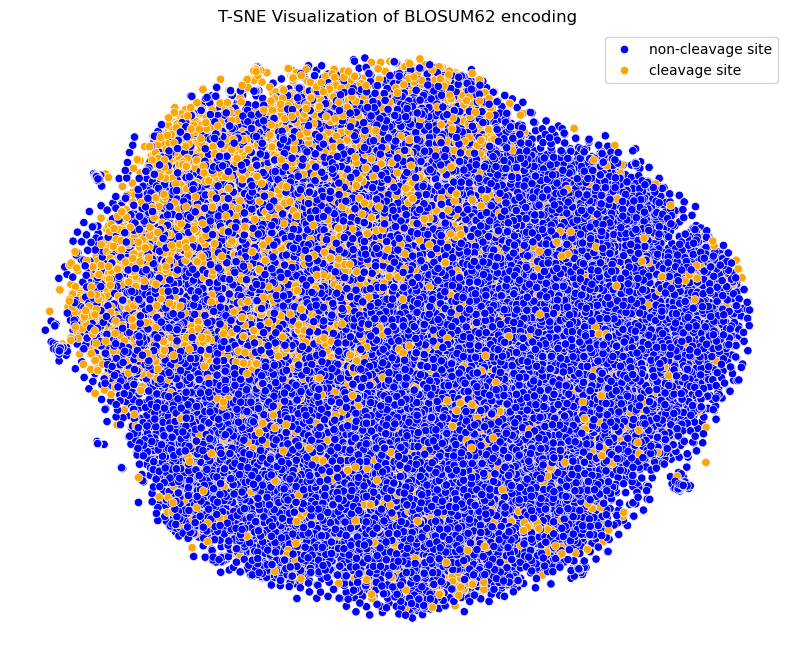

<Figure size 640x480 with 0 Axes>

In [80]:
tsne_plot(embedding_standard,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding")
#plt.savefig(f'blosum62_tsne_PCA_multi50-500.png',format='png',bbox_inches='tight',dpi=300)

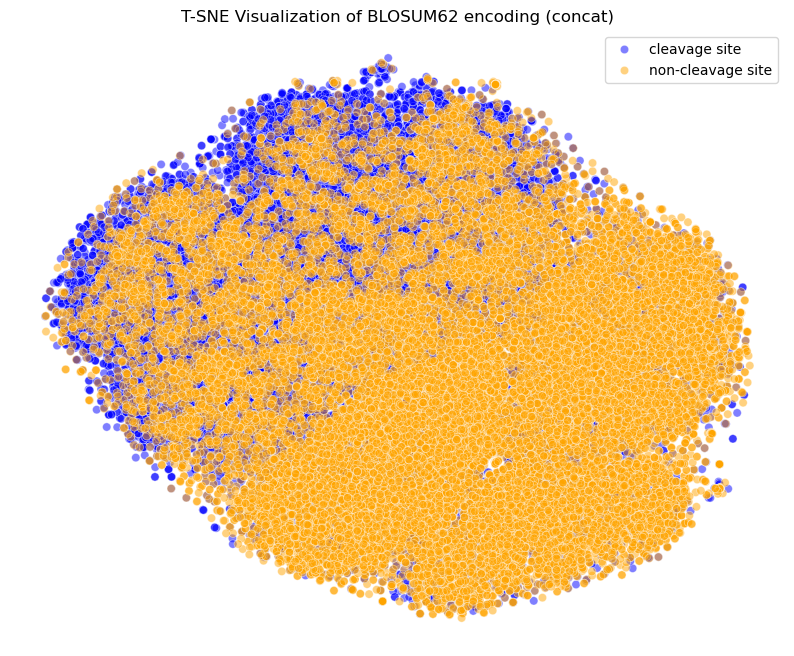

<Figure size 640x480 with 0 Axes>

In [12]:
tsne_plot(blosum62_emb_multi,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (concat)")
plt.savefig(f'blosum62concat_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

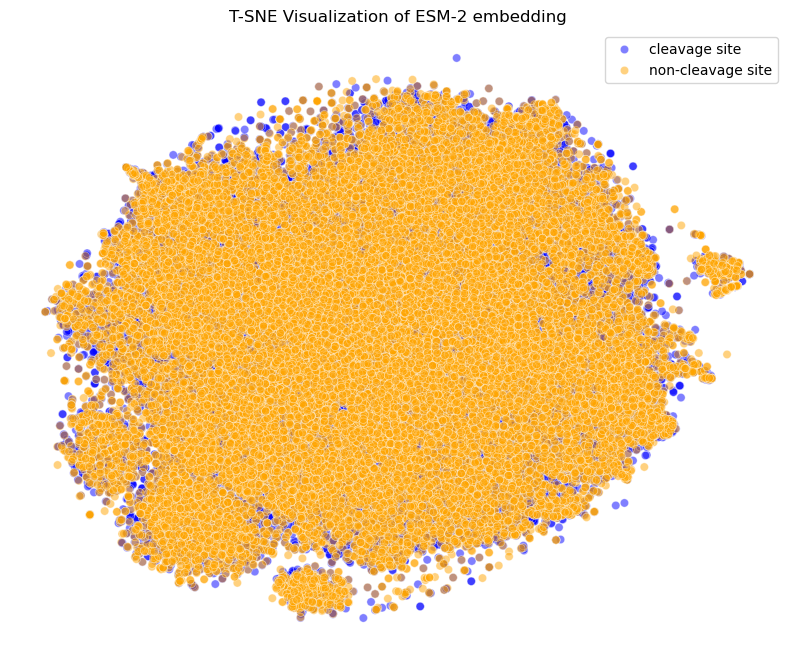

<Figure size 640x480 with 0 Axes>

In [20]:
tsne_plot(esm2_emb_multi,blosum_labels,title="T-SNE Visualization of ESM-2 embedding")
plt.savefig(f'esm2avg_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

In [2]:
tsne_plot(esm2conc_aff500,labels,title="T-SNE Visualization of ESM-2 embedding (concat)")
#plt.savefig(f'esm2avg_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

NameError: name 'esm2conc_aff500' is not defined